<a href="https://colab.research.google.com/github/Shree1785/CSL701-CE49-Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Bhagyashree Shrikrishna Wagle

Batch : CE3

Roll Number : CE49



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Load the Palmer Penguins Extended dataset
df = pd.read_csv("/content/palmerpenguins_extended.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (3430, 11)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:

# Handle missing values
original_len = len(df)

df = df.dropna(
    subset=[
        'bill_length_mm',
        'bill_depth_mm',
        'flipper_length_mm',
        'body_mass_g',
        'species'
    ]
).copy()

print(f"Dropped {original_len - len(df)} rows containing missing values.")

# Select features and target
X = df[
    [
        'bill_length_mm',
        'bill_depth_mm',
        'flipper_length_mm',
        'body_mass_g'
    ]
]

y = df['species']

# Encode species labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Target Classes:", le.classes_)
print("Feature Shape:", X.shape)
print("Target Shape:", y_encoded.shape)

display(X.head())


Dropped 0 rows containing missing values.
Target Classes: ['Adelie' 'Chinstrap' 'Gentoo']
Feature Shape: (3430, 4)
Target Shape: (3430,)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,53.4,17.8,219.0,5687.0
1,49.3,18.1,245.0,6811.0
2,55.7,16.6,226.0,5388.0
3,38.0,15.6,221.0,6262.0
4,60.7,17.9,177.0,4811.0


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")


Training set shape: (2744, 4)
Testing set shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:

# Initialize CART classifier using Gini criterion
cart_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

# Train the model
cart_model.fit(X_train, y_train)

# Make predictions
y_pred_cart = cart_model.predict(X_test)

print("CART Classifier Model successfully trained.")


CART Classifier Model successfully trained.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [ ]:

# Calculate accuracy, confusion matrix and classification report
accuracy = accuracy_score(y_test, y_pred_cart)

cm = confusion_matrix(y_test, y_pred_cart)

report = classification_report(
    y_test,
    y_pred_cart,
    target_names=le.classes_,
    zero_division=0
)

print(f"Accuracy of CART Classifier: {accuracy:.4f}\n")

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(report)


Accuracy of CART Classifier: 0.5671

Confusion Matrix:
[[209   2 101]
 [ 66   3  56]
 [ 68   4 177]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.61      0.67      0.64       312
   Chinstrap       0.33      0.02      0.04       125
      Gentoo       0.53      0.71      0.61       249

    accuracy                           0.57       686
   macro avg       0.49      0.47      0.43       686
weighted avg       0.53      0.57      0.52       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


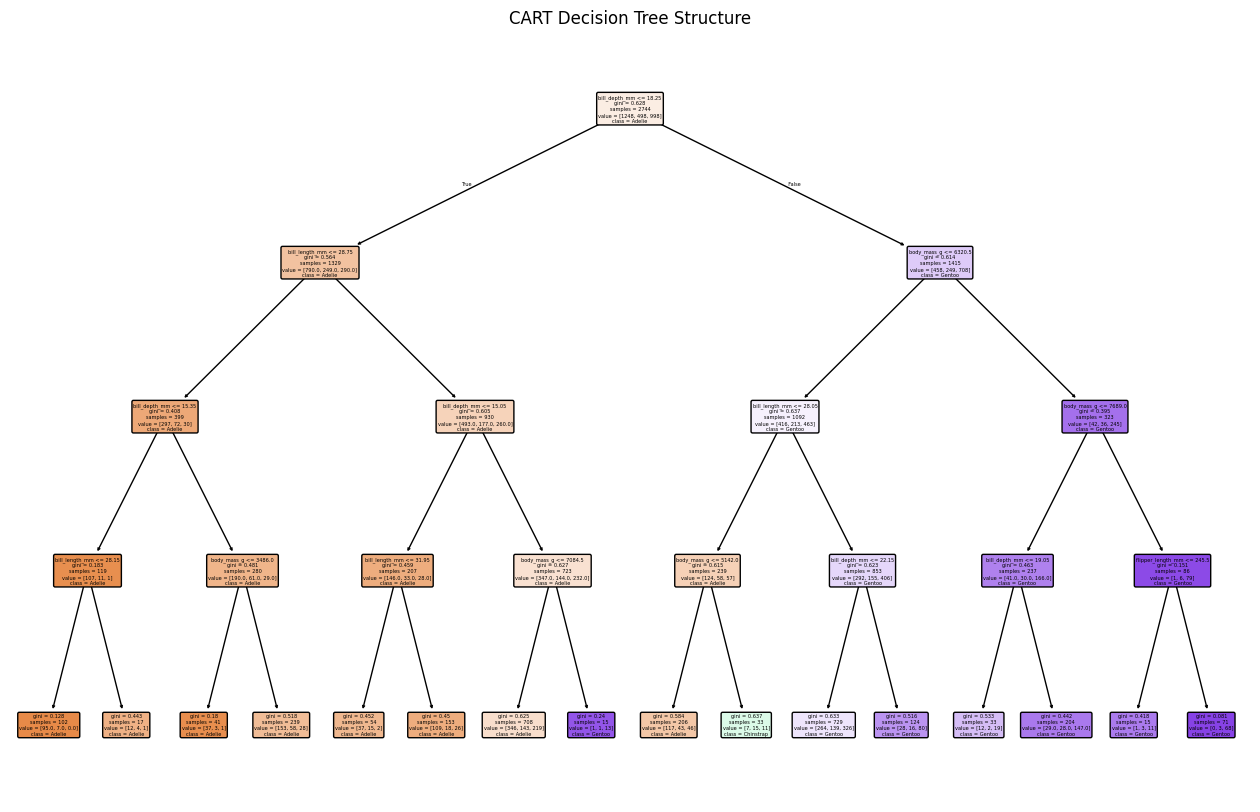

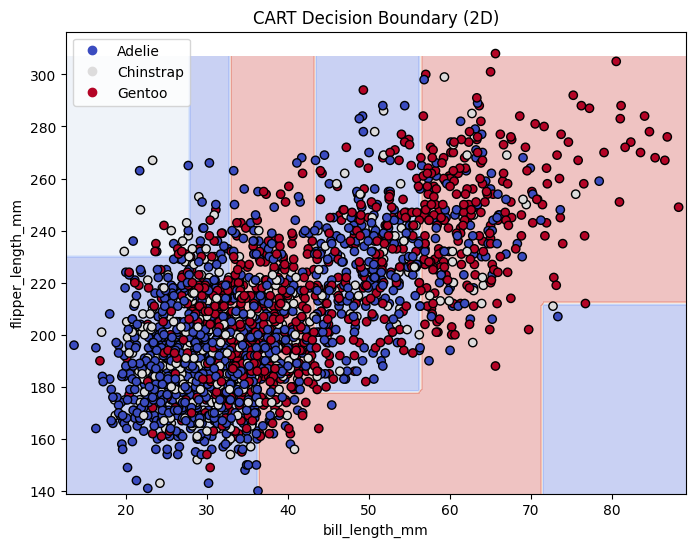

In [ ]:

# 1. Visualize the Decision Tree
plt.figure(figsize=(16, 10))

plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True
)

plt.title("CART Decision Tree Structure")
plt.show()


# 2. Select two features for decision boundary
X_2d = df[['bill_length_mm', 'flipper_length_mm']]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y_encoded
)

# Train CART using two features
cart_2d = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

cart_2d.fit(X_train_2d, y_train_2d)


# 3. Function to plot decision boundary
def plot_decision_boundary(model, X, y, title):

    x_min = X.iloc[:, 0].min() - 1
    x_max = X.iloc[:, 0].max() + 1

    y_min = X.iloc[:, 1].min() - 1
    y_max = X.iloc[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.5),
        np.arange(y_min, y_max, 2)
    )

    grid = pd.DataFrame(
        np.c_[xx.ravel(), yy.ravel()],
        columns=X.columns
    )

    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    plt.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap=plt.cm.coolwarm
    )

    scatter = plt.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=y,
        edgecolors='k',
        cmap=plt.cm.coolwarm
    )

    plt.xlabel(X.columns[0])
    plt.ylabel(X.columns[1])
    plt.title(title)

    plt.legend(
        handles=scatter.legend_elements()[0],
        labels=list(le.classes_)
    )


# 4. Plot CART decision boundary
plt.figure(figsize=(8, 6))

plot_decision_boundary(
    cart_2d,
    X_train_2d,
    y_train_2d,
    "CART Decision Boundary (2D)"
)

plt.show()


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

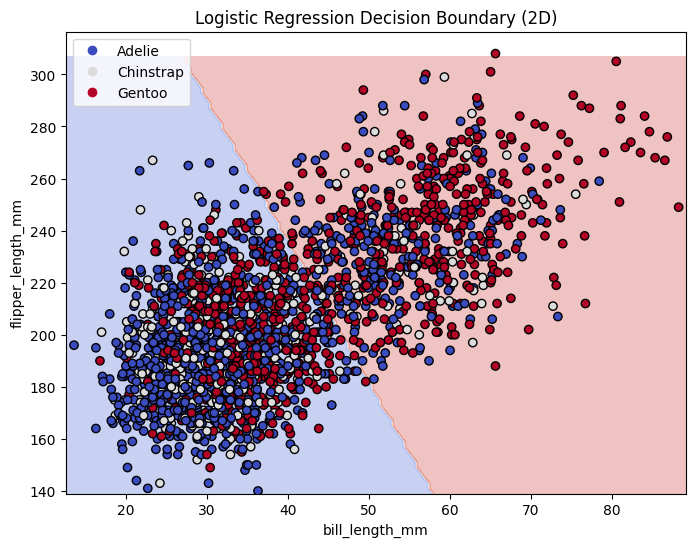

In [ ]:

# Train Logistic Regression Model
log_reg_2d = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg_2d.fit(X_train_2d, y_train_2d)

# Plot Logistic Regression decision boundary
plt.figure(figsize=(8, 6))

plot_decision_boundary(
    log_reg_2d,
    X_train_2d,
    y_train_2d,
    "Logistic Regression Decision Boundary (2D)"
)

plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

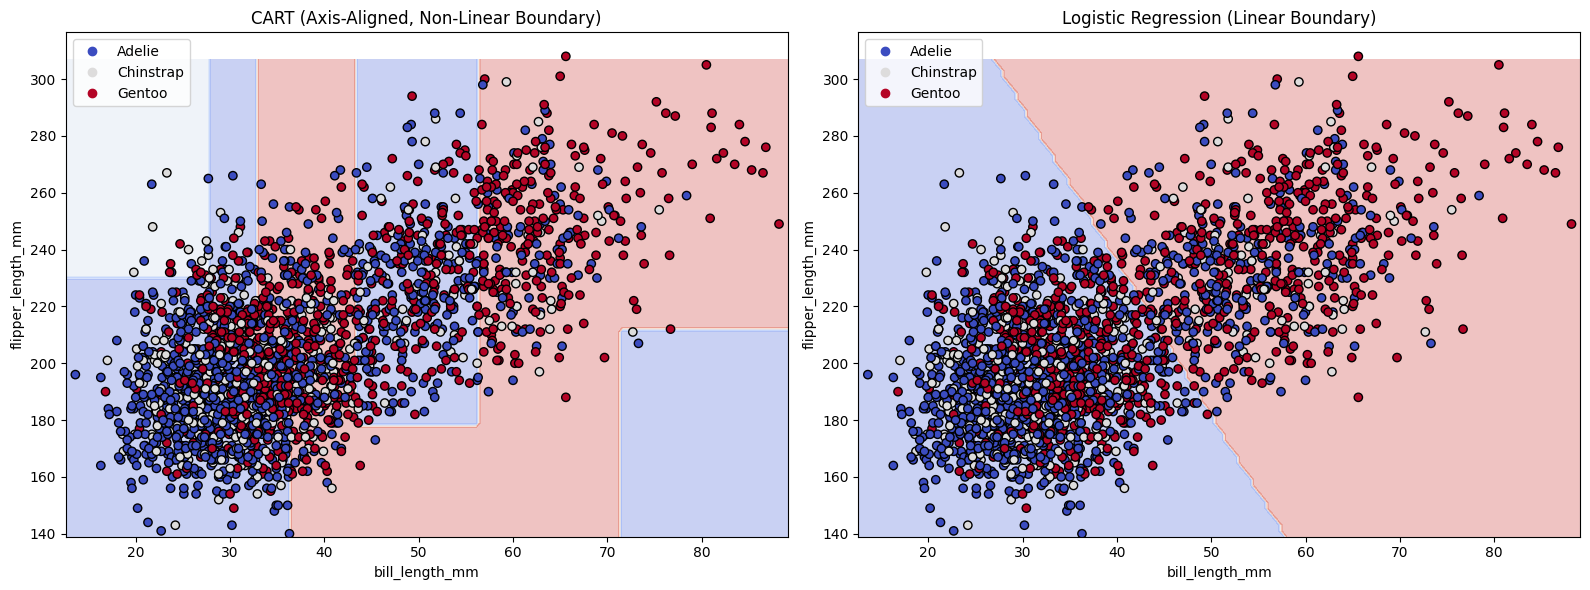

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CART decision boundary
plt.subplot(1, 2, 1)

plot_decision_boundary(
    cart_2d,
    X_train_2d,
    y_train_2d,
    "CART (Axis-Aligned, Non-Linear Boundary)"
)

# Logistic Regression decision boundary
plt.subplot(1, 2, 2)

plot_decision_boundary(
    log_reg_2d,
    X_train_2d,
    y_train_2d,
    "Logistic Regression (Linear Boundary)"
)

plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [ ]:

# Train Logistic Regression using all four features
log_reg_full = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg_full.fit(X_train, y_train)

# Predict test data
y_pred_lr = log_reg_full.predict(X_test)

# Calculate Logistic Regression metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_cm = confusion_matrix(y_test, y_pred_lr)

lr_report = classification_report(
    y_test,
    y_pred_lr,
    target_names=le.classes_,
    zero_division=0
)

# Display performance comparison
print("=" * 60)
print("PERFORMANCE COMPARISON (CART vs LOGISTIC REGRESSION)")
print("=" * 60)

print(f"CART Accuracy:                {accuracy:.4f}")
print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}")

print("\n" + "-" * 60)

print("CART Confusion Matrix:")
print(cm)

print("\nLogistic Regression Confusion Matrix:")
print(lr_cm)

print("\n" + "-" * 60)

print("CART Classification Report:")
print(report)

print("\nLogistic Regression Classification Report:")
print(lr_report)

print("=" * 60)


PERFORMANCE COMPARISON (CART vs LOGISTIC REGRESSION)
CART Accuracy:                0.5671
Logistic Regression Accuracy: 0.5787

------------------------------------------------------------
CART Confusion Matrix:
[[209   2 101]
 [ 66   3  56]
 [ 68   4 177]]

Logistic Regression Confusion Matrix:
[[239   0  73]
 [ 85   0  40]
 [ 91   0 158]]

------------------------------------------------------------
CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.61      0.67      0.64       312
   Chinstrap       0.33      0.02      0.04       125
      Gentoo       0.53      0.71      0.61       249

    accuracy                           0.57       686
   macro avg       0.49      0.47      0.43       686
weighted avg       0.53      0.57      0.52       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.58      0.77      0.66       312
   Chinstrap       0.00      0.00

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.